In [1]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.9/28.9 MB 102.9 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 82.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [catboost]2/3 [catboost]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import catboost
import pandas as pd
import sklearn
import numpy as np
from sklearn.model_selection import GroupKFold

RANDOM_STATE = 42
TARGET = "vae_positive_local"
INCLUDE_DEMOGRAPHICS = False

DATA_PATH = "../../../data/merges/CS_PSEO_IPEDS_BLS_ETPL_merged.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

labeled = df.dropna(subset=[TARGET]).copy()
y = labeled[TARGET].astype(int)
groups = labeled["UNITID"]

cv = GroupKFold(n_splits=5)

print("DATASET OVERVIEW")
print("=" * 50)
print(f"Total programs: {len(df):,}")
print(f"Labeled programs: {len(labeled):,}")
print(f"Unique institutions: {groups.nunique():,}")
print(f"Missing labels: {df[TARGET].isna().sum():,}")

print("\nTARGET DISTRIBUTION")
print("=" * 50)
print(y.value_counts().sort_index())

print("\nTARGET DISTRIBUTION (%)")
print("=" * 50)
print(y.value_counts(normalize=True).sort_index().mul(100).round(2))

DATASET OVERVIEW
Total programs: 26,678
Labeled programs: 7,024
Unique institutions: 2,079
Missing labels: 19,654

TARGET DISTRIBUTION
vae_positive_local
0    1521
1    5503
Name: count, dtype: int64

TARGET DISTRIBUTION (%)
vae_positive_local
0    21.65
1    78.35
Name: proportion, dtype: float64


In [4]:
drop_cols = [
    "CREDLEV", "CREDDESC", "CURROPER",
    "CIPCODE_str", "cip4", "CIP_family", "cip_code",
    "cip_2digit", "ST_FIPS",
    "TUITIONFEE_OUT_was_missing", "PCTFLOAN_was_missing",
    "DISTANCEONLY", "LOCALE_-3.0", "PREDDEG_4.0",
    "HIGHDEG_0.0", "has_pseo_match", "cip_match_level",
    "offers_undergrad", "enrolls_ft_undergrad",
    "offers_distance_courses",
    "xw_occ_mean_wage", "y1_earnings_natl_cip_family",
    "y5_earnings_natl_cip_family", "weeks_to_complete",
    "ay_tuition_indistrict", "ay_fee_indistrict",
    "ay_credithr_indistrict", "ay_pub_tuitfee_indistrict",
    "etpl_state_completion_median",
    "etpl_state_employment_q2_median",
    "etpl_state_earnings_median",
    "etpl_state_contact_hours_median",
    "etpl_state_tuition_median",
    "etpl_natl_completion_median",
    "etpl_natl_employment_q2_median",
    "etpl_natl_earnings_median",
    "etpl_natl_contact_hours_median",
    "etpl_natl_tuition_median",
    "local_earnings_index_state",
    "local_earnings_index_region",
    "prog_tuition_fees", "total_prog_cost",
    "ADM_RATE", "program_slot",
    "length_unit_code", "xw_has_hot_technology"
]

df = df.drop(columns=drop_cols, errors="ignore")

LEAKAGE = [
    "EARN_MDN_1YR", "EARN_MDN_5YR",
    "EARN_MDN_HI_1YR", "EARN_COUNT_WNE_1YR",
    "EARN_COUNT_WNE_5YR",
    "y1_earnings_program", "y5_earnings_program",
    "y1_earnings_program_status",
    "y5_earnings_program_status",
    "earnings_1yr", "earnings_1yr_local_adj",
    "value_added_earnings_local",
    "earnings_vs_local_field",
    "vae_positive_local", "passes_vae_local"
]

ID_TEXT = [
    "UNITID", "OPEID6", "INSTNM", "city", "ZIP",
    "LATITUDE", "LONGITUDE", "CIPDESC",
    "xw_top_occupations", "program_text"
]

FAIRNESS_ONLY = ["HBCU", "TRIBAL", "ANNHI", "NANTI"]

DUPLICATE_FORMAT = [
    "control", "sector", "iclevel", "bea_region",
    "state", "highest_offering", "etpl_bench_level",
    "local_index_level", "length_unit",
    "price_reporting",
    "y1_earnings_natl_benchmark_level",
    "y5_earnings_natl_benchmark_level"
]

ETPL_PROGRAM = [
    c for c in df.columns if c.startswith("etpl_prog_")
]

DEMOGRAPHICS = [
    c for c in df.columns
    if c.startswith("UGDS_")
    and c not in ["UGDS_was_missing", "UGDS"]
]

exclude = set(LEAKAGE + ID_TEXT + FAIRNESS_ONLY + DUPLICATE_FORMAT + ETPL_PROGRAM)

if not INCLUDE_DEMOGRAPHICS:
    exclude |= set(DEMOGRAPHICS)

numeric = df[[c for c in df.columns if c not in exclude]].copy()

for c in numeric.columns:
    if numeric[c].dtype == object:
        numeric[c] = numeric[c].map({
            True: 1, False: 0,
            "True": 1, "False": 0
        })

numeric = numeric.apply(pd.to_numeric, errors="coerce")
numeric = numeric.loc[:, numeric.notna().any()]

NUMERIC_FEATURES = numeric.columns.tolist()

df[NUMERIC_FEATURES] = numeric
labeled[NUMERIC_FEATURES] = numeric.loc[labeled.index]

X = labeled[NUMERIC_FEATURES].copy()

print("FEATURE SELECTION RESULTS")
print("=" * 50)
print(f"Numeric features: {len(NUMERIC_FEATURES)}")
print(f"Training shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Institutions: {groups.nunique():,}")
print(f"Demographics included: {INCLUDE_DEMOGRAPHICS}")
print(f"Missing feature cells: {X.isna().sum().sum():,}")

print("\nFEATURE SAMPLE")
print(NUMERIC_FEATURES[:20])

print("\nTARGET LEAKAGE CHECK")
print(set(NUMERIC_FEATURES) & set(LEAKAGE))

FEATURE SELECTION RESULTS
Numeric features: 144
Training shape: (7024, 144)
Target shape: (7024,)
Institutions: 2,079
Demographics included: False
Missing feature cells: 97,312

FEATURE SAMPLE
['MAIN', 'CIPCODE', 'IPEDSCOUNT1', 'IPEDSCOUNT2', 'NUMBRANCH', 'PBI', 'AANAPII', 'HSI', 'UGDS', 'COSTT4_A', 'TUITIONFEE_IN', 'TUITIONFEE_OUT', 'INEXPFTE', 'AVGFACSAL', 'PFTFAC', 'PCTPELL', 'C150_L4', 'RET_FTL4', 'RET_PTL4', 'PCTFLOAN']

TARGET LEAKAGE CHECK
set()


In [5]:
from catboost import CatBoostClassifier

BALANCE = True

n_negative = (y == 0).sum()
n_positive = (y == 1).sum()

scale_pos_weight = (n_negative / n_positive if BALANCE else 1.0)

catboost_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    scale_pos_weight=scale_pos_weight,
    random_seed=RANDOM_STATE,
    verbose=False,
    thread_count=-1
)

print("CATBOOST CONFIGURATION")
print("=" * 50)
print(f"Class balancing enabled: {BALANCE}")
print(f"Negative class count: {n_negative:,}")
print(f"Positive class count: {n_positive:,}")
print(f"Positive class weight: {scale_pos_weight:.4f}")
print(f"Cross-validation: {cv.n_splits} folds")
print(f"Grouping variable: UNITID")
print(f"Training features: {X.shape[1]}")
print(f"Training observations: {X.shape[0]:,}")

print("\nCROSS-VALIDATION FOLD CHECK")
print("=" * 50)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    train_schools = set(groups.iloc[train_idx])
    test_schools = set(groups.iloc[test_idx])

    overlap = train_schools & test_schools

    print(
        f"Fold {fold}: "
        f"Train={len(train_idx):,}, "
        f"Test={len(test_idx):,}, "
        f"School overlap={len(overlap)}"
    )

CATBOOST CONFIGURATION
Class balancing enabled: True
Negative class count: 1,521
Positive class count: 5,503
Positive class weight: 0.2764
Cross-validation: 5 folds
Grouping variable: UNITID
Training features: 144
Training observations: 7,024

CROSS-VALIDATION FOLD CHECK
Fold 1: Train=5,619, Test=1,405, School overlap=0
Fold 2: Train=5,619, Test=1,405, School overlap=0
Fold 3: Train=5,619, Test=1,405, School overlap=0
Fold 4: Train=5,619, Test=1,405, School overlap=0
Fold 5: Train=5,620, Test=1,404, School overlap=0


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

oof_prob = np.zeros(len(y))
oof_pred = np.zeros(len(y), dtype=int)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    print(f"Training Fold {fold}/5...")

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    model = CatBoostClassifier(**catboost_model.get_params())

    model.fit(X_train, y_train)

    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)

    oof_prob[test_idx] = prob
    oof_pred[test_idx] = pred

    results = {
        "Fold": fold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    }

    fold_results.append(results)

    print(
        f"  ROC-AUC: {results['ROC-AUC']:.4f} | "
        f"F1: {results['F1']:.4f}"
    )

fold_df = pd.DataFrame(fold_results)

print("\nCATBOOST — FOLD RESULTS")
print("=" * 65)
print(fold_df.round(4).to_string(index=False))

print("\nCATBOOST — OVERALL OUT-OF-FOLD RESULTS")
print("=" * 65)

overall_metrics = {
    "Accuracy": accuracy_score(y, oof_pred),
    "Precision": precision_score(y, oof_pred),
    "Recall": recall_score(y, oof_pred),
    "F1": f1_score(y, oof_pred),
    "ROC-AUC": roc_auc_score(y, oof_prob)
}

for metric, value in overall_metrics.items():
    print(f"{metric}: {value:.4f}")

Training Fold 1/5...
  ROC-AUC: 0.9674 | F1: 0.9530
Training Fold 2/5...
  ROC-AUC: 0.9582 | F1: 0.9475
Training Fold 3/5...
  ROC-AUC: 0.9572 | F1: 0.9493
Training Fold 4/5...
  ROC-AUC: 0.9546 | F1: 0.9409
Training Fold 5/5...
  ROC-AUC: 0.9630 | F1: 0.9574

CATBOOST — FOLD RESULTS
 Fold  Accuracy  Precision  Recall     F1  ROC-AUC
    1    0.9267     0.9569  0.9491 0.9530   0.9674
    2    0.9189     0.9554  0.9397 0.9475   0.9582
    3    0.9203     0.9624  0.9366 0.9493   0.9572
    4    0.9082     0.9509  0.9310 0.9409   0.9546
    5    0.9338     0.9535  0.9614 0.9574   0.9630

CATBOOST — OVERALL OUT-OF-FOLD RESULTS
Accuracy: 0.9216
Precision: 0.9558
Recall: 0.9435
F1: 0.9496
ROC-AUC: 0.9602


In [7]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import time

param_distributions = {
    "iterations": randint(300, 1001),
    "depth": randint(4, 9),
    "learning_rate": uniform(0.02, 0.13),
    "l2_leaf_reg": uniform(2, 10),
    "random_strength": uniform(0, 2)
}

base_model = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    scale_pos_weight=scale_pos_weight,
    random_seed=RANDOM_STATE,
    verbose=False,
    thread_count=2,
    allow_writing_files=False
)

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="roc_auc",
    cv=cv,
    refit=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

start_time = time.time()

search.fit(X, y, groups=groups)

elapsed = time.time() - start_time

print("\nCATBOOST HYPERPARAMETER SEARCH")
print("=" * 55)
print(f"Best CV ROC-AUC: {search.best_score_:.4f}")
print(f"Search time: {elapsed / 60:.2f} minutes")

print("\nBEST PARAMETERS")
for key, value in search.best_params_.items():
    print(f"{key}: {value}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits

CATBOOST HYPERPARAMETER SEARCH
Best CV ROC-AUC: 0.9623
Search time: 14.19 minutes

BEST PARAMETERS
depth: 8
iterations: 860
l2_leaf_reg: 7.2477466025838915
learning_rate: 0.07198192632298321
random_strength: 0.09333132642723085


In [8]:
from sklearn.metrics import (confusion_matrix)

best_params = search.best_params_

tuned_oof_prob = np.zeros(len(y))
tuned_oof_pred = np.zeros(len(y), dtype=int)

tuned_fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    print(f"Evaluating tuned CatBoost — Fold {fold}/5...")

    model = CatBoostClassifier(
        **best_params,
        loss_function="Logloss",
        eval_metric="AUC",
        scale_pos_weight=scale_pos_weight,
        random_seed=RANDOM_STATE,
        verbose=False,
        thread_count=-1,
        allow_writing_files=False
    )

    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    prob = model.predict_proba(X.iloc[test_idx])[:, 1]
    pred = (prob >= 0.5).astype(int)

    tuned_oof_prob[test_idx] = prob
    tuned_oof_pred[test_idx] = pred

    tuned_fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y.iloc[test_idx], pred),
        "Precision": precision_score(y.iloc[test_idx], pred),
        "Recall": recall_score(y.iloc[test_idx], pred),
        "F1": f1_score(y.iloc[test_idx], pred),
        "ROC-AUC": roc_auc_score(y.iloc[test_idx], prob)
    })

tuned_fold_df = pd.DataFrame(tuned_fold_results)

print("\nTUNED CATBOOST — FOLD RESULTS")
print("=" * 65)
print(tuned_fold_df.round(4).to_string(index=False))

print("\nTUNED CATBOOST — OVERALL OUT-OF-FOLD RESULTS")
print("=" * 65)

tuned_metrics = {
    "Accuracy": accuracy_score(y, tuned_oof_pred),
    "Precision": precision_score(y, tuned_oof_pred),
    "Recall": recall_score(y, tuned_oof_pred),
    "F1": f1_score(y, tuned_oof_pred),
    "ROC-AUC": roc_auc_score(y, tuned_oof_prob)
}

for metric, value in tuned_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print("=" * 65)
print(confusion_matrix(y, tuned_oof_pred))

Evaluating tuned CatBoost — Fold 1/5...
Evaluating tuned CatBoost — Fold 2/5...
Evaluating tuned CatBoost — Fold 3/5...
Evaluating tuned CatBoost — Fold 4/5...
Evaluating tuned CatBoost — Fold 5/5...

TUNED CATBOOST — FOLD RESULTS
 Fold  Accuracy  Precision  Recall     F1  ROC-AUC
    1    0.9267     0.9519  0.9545 0.9532   0.9680
    2    0.9231     0.9490  0.9525 0.9507   0.9619
    3    0.9302     0.9612  0.9509 0.9560   0.9629
    4    0.9189     0.9507  0.9456 0.9481   0.9565
    5    0.9302     0.9467  0.9641 0.9553   0.9622

TUNED CATBOOST — OVERALL OUT-OF-FOLD RESULTS
Accuracy: 0.9258
Precision: 0.9519
Recall: 0.9535
F1: 0.9527
ROC-AUC: 0.9623

CONFUSION MATRIX
[[1256  265]
 [ 256 5247]]


CATBOOST — TOP 20 IMPORTANT FEATURES
                   Feature  Importance
y1_earnings_natl_benchmark    7.962796
      local_earnings_index    6.610411
y5_earnings_natl_benchmark    4.828030
                   PCTPELL    4.780415
               IPEDSCOUNT2    2.659134
 etpl_natl_n_with_outcomes    2.652235
                   C150_L4    2.427681
               IPEDSCOUNT1    2.316714
  etpl_bench_employment_q2    2.315215
        etpl_bench_tuition    2.217448
                  RET_FTL4    2.163546
                  INEXPFTE    2.066576
 has_institution_cip_match    1.992178
       etpl_bench_earnings    1.987774
     etpl_bench_completion    1.952957
      etpl_natl_n_programs    1.791594
                   STUFACR    1.771325
                 AVGFACSAL    1.683913
                  PCTFLOAN    1.638475
                      UGDS    1.584825


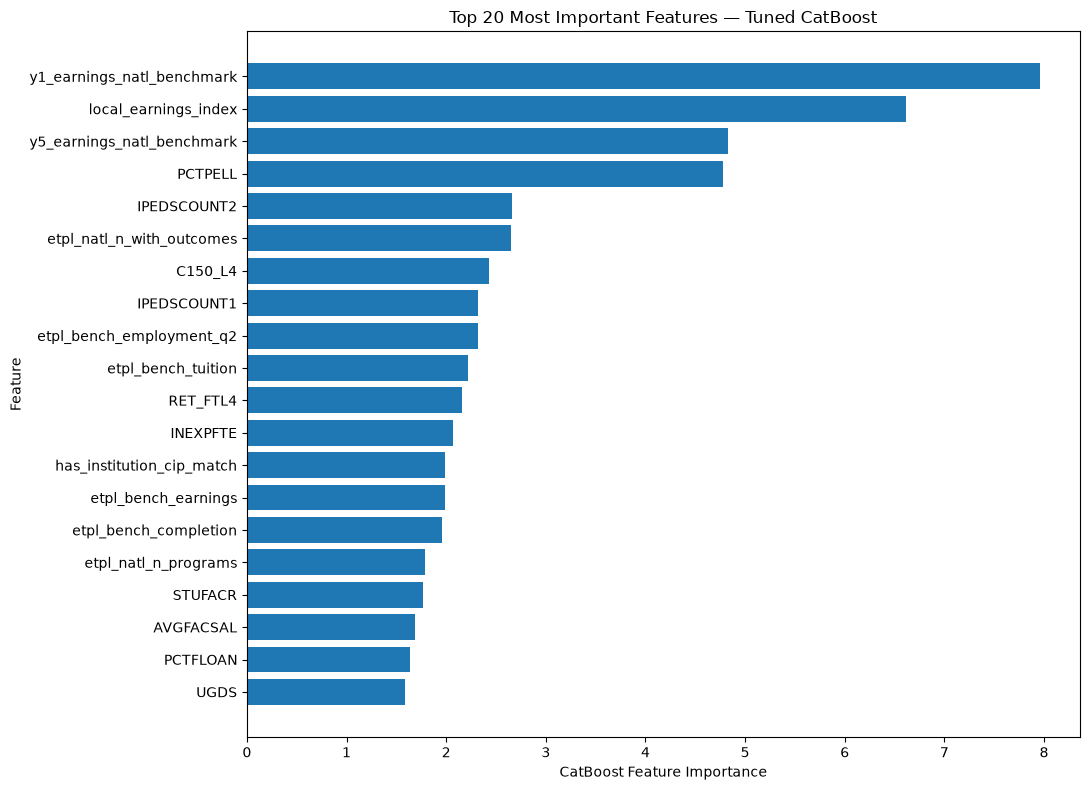

In [9]:
import matplotlib.pyplot as plt

best_model = search.best_estimator_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.get_feature_importance()
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("CATBOOST — TOP 20 IMPORTANT FEATURES")
print("=" * 65)
print(feature_importance.head(20).to_string(index=False))

top_features = feature_importance.head(20)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("CatBoost Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Most Important Features — Tuned CatBoost")
plt.tight_layout()
plt.show()

In [10]:
features_to_check = [
    "y1_earnings_natl_benchmark",
    "y5_earnings_natl_benchmark",
    "local_earnings_index",
    "etpl_bench_earnings",
    "etpl_bench_employment_q2"
]

print("FEATURE LEAKAGE REVIEW")
print("=" * 70)

for feature in features_to_check:
    if feature not in X.columns:
        print(f"\n{feature}: NOT FOUND")
        continue

    values = X[feature]

    print(f"\nFeature: {feature}")
    print("-" * 70)

    print(f"Missing values: {values.isna().sum():,}")
    print(f"Unique values: {values.nunique():,}")
    print(f"Minimum: {values.min():.4f}")
    print(f"Median: {values.median():.4f}")
    print(f"Maximum: {values.max():.4f}")

    print("\nMean by target class:")
    print(
        pd.DataFrame({
            "Feature": values,
            "Target": y
        }).groupby("Target")["Feature"].mean()
    )

print("\nCORRELATION WITH TARGET")
print("=" * 70)

available_features = [
    f for f in features_to_check if f in X.columns
]

correlations = X[available_features].corrwith(y)

print(
    correlations.sort_values(
        key=lambda s: s.abs(),
        ascending=False
    ).round(4)
)

FEATURE LEAKAGE REVIEW

Feature: y1_earnings_natl_benchmark
----------------------------------------------------------------------
Missing values: 1
Unique values: 199
Minimum: 22662.5000
Median: 35822.8037
Maximum: 111205.0000

Mean by target class:
Target
0    28821.372534
1    39411.572163
Name: Feature, dtype: float64

Feature: y5_earnings_natl_benchmark
----------------------------------------------------------------------
Missing values: 3
Unique values: 188
Minimum: 31690.7143
Median: 49441.7429
Maximum: 107036.3636

Mean by target class:
Target
0    36660.444378
1    50858.346031
Name: Feature, dtype: float64

Feature: local_earnings_index
----------------------------------------------------------------------
Missing values: 0
Unique values: 43
Minimum: 0.4621
Median: 0.9956
Maximum: 1.2002

Mean by target class:
Target
0    1.016188
1    0.979456
Name: Feature, dtype: float64

Feature: etpl_bench_earnings
----------------------------------------------------------------------
M

In [11]:
audit_columns = [
    "y1_earnings_program",
    "earnings_1yr",
    "earnings_1yr_local_adj",
    "value_added_earnings_local",
    "y1_earnings_natl_benchmark",
    "y5_earnings_natl_benchmark",
    "local_earnings_index",
    "vae_positive_local"
]

available = [c for c in audit_columns if c in labeled.columns]

audit_df = labeled[available].copy()

for col in available:
    audit_df[col] = pd.to_numeric(
        audit_df[col], errors="coerce"
    )

print("TARGET AND BENCHMARK AUDIT")
print("=" * 65)

print("\nAVAILABLE COLUMNS")
print(available)

print("\nCORRELATION MATRIX")
print(
    audit_df.corr().round(4).to_string()
)

print("\nNON-MISSING COUNTS")
print(audit_df.notna().sum().to_string())

print("\nSAMPLE ROWS")
print(audit_df.head(10).round(3).to_string(index=False))

TARGET AND BENCHMARK AUDIT

AVAILABLE COLUMNS
['y1_earnings_program', 'earnings_1yr', 'earnings_1yr_local_adj', 'value_added_earnings_local', 'y1_earnings_natl_benchmark', 'y5_earnings_natl_benchmark', 'local_earnings_index', 'vae_positive_local']

CORRELATION MATRIX
                            y1_earnings_program  earnings_1yr  earnings_1yr_local_adj  value_added_earnings_local  y1_earnings_natl_benchmark  y5_earnings_natl_benchmark  local_earnings_index  vae_positive_local
y1_earnings_program                      1.0000        0.9578                  0.9386                      0.9386                      0.6509                      0.6059               -0.0043              0.2347
earnings_1yr                             0.9578        1.0000                  0.9569                      0.9569                      0.6689                      0.6750                0.1069              0.5857
earnings_1yr_local_adj                   0.9386        0.9569                  1.0000           

In [12]:
THRESHOLD = 23475

reconstructed_earnings = (
    labeled["earnings_1yr"] /
    labeled["local_earnings_index"]
)

reconstructed_target = (
    reconstructed_earnings > THRESHOLD
).astype(int)

target_matches = (
    reconstructed_target == y
)

print("TARGET CONSTRUCTION VERIFICATION")
print("=" * 60)

print(f"Total observations: {len(y):,}")
print(f"Matching labels: {target_matches.sum():,}")
print(f"Mismatched labels: {(~target_matches).sum():,}")
print(f"Match percentage: {target_matches.mean() * 100:.2f}%")

earnings_difference = (
    reconstructed_earnings -
    labeled["earnings_1yr_local_adj"]
).abs()

print("\nADJUSTED EARNINGS VERIFICATION")
print("=" * 60)

print(f"Maximum absolute difference: ${earnings_difference.max():.6f}")
print(f"Mean absolute difference: ${earnings_difference.mean():.6f}")

value_added_difference = (
    labeled["value_added_earnings_local"] -
    (labeled["earnings_1yr_local_adj"] - THRESHOLD)
).abs()

print("\nVALUE-ADDED VERIFICATION")
print("=" * 60)

print(f"Maximum absolute difference: ${value_added_difference.max():.6f}")
print(f"Mean absolute difference: ${value_added_difference.mean():.6f}")

TARGET CONSTRUCTION VERIFICATION
Total observations: 7,024
Matching labels: 7,024
Mismatched labels: 0
Match percentage: 100.00%

ADJUSTED EARNINGS VERIFICATION
Maximum absolute difference: $0.000000
Mean absolute difference: $0.000000

VALUE-ADDED VERIFICATION
Maximum absolute difference: $0.000000
Mean absolute difference: $0.000000


In [13]:
benchmark_cols = [
    "y1_earnings_natl_benchmark",
    "y5_earnings_natl_benchmark"
]

print("NATIONAL EARNINGS BENCHMARK AUDIT")
print("=" * 65)

for col in benchmark_cols:
    print(f"\nFEATURE: {col}")
    print("-" * 65)

    counts = labeled[col].value_counts(dropna=True)

    print(f"Unique benchmark values: {counts.size:,}")
    print(f"Programs per value (median): {counts.median():.0f}")
    print(f"Programs per value (maximum): {counts.max():,}")

    valid = labeled[
        ["earnings_1yr", col]
    ].dropna()

    exact_matches = np.isclose(
        valid["earnings_1yr"],
        valid[col],
        rtol=0,
        atol=0.01
    )

    print(f"Exact matches to earnings_1yr: {exact_matches.sum():,}")
    print(f"Compared observations: {len(valid):,}")

print("\nBENCHMARK VARIATION WITHIN PROGRAM GROUPS")
print("=" * 65)

if "CIPCODE" in labeled.columns:
    for col in benchmark_cols:
        variation = (
            labeled.groupby("CIPCODE")[col]
            .nunique(dropna=True)
        )

        print(f"\n{col}")
        print(f"CIP groups: {len(variation):,}")
        print(
            "Groups with one or fewer benchmark values:",
            (variation <= 1).sum()
        )
        print(
            "Groups with multiple benchmark values:",
            (variation > 1).sum()
        )

NATIONAL EARNINGS BENCHMARK AUDIT

FEATURE: y1_earnings_natl_benchmark
-----------------------------------------------------------------
Unique benchmark values: 199
Programs per value (median): 4
Programs per value (maximum): 875
Exact matches to earnings_1yr: 13
Compared observations: 7,023

FEATURE: y5_earnings_natl_benchmark
-----------------------------------------------------------------
Unique benchmark values: 188
Programs per value (median): 4
Programs per value (maximum): 875
Exact matches to earnings_1yr: 0
Compared observations: 7,021

BENCHMARK VARIATION WITHIN PROGRAM GROUPS

y1_earnings_natl_benchmark
CIP groups: 202
Groups with one or fewer benchmark values: 202
Groups with multiple benchmark values: 0

y5_earnings_natl_benchmark
CIP groups: 202
Groups with one or fewer benchmark values: 202
Groups with multiple benchmark values: 0
